# Exploratory data checks

This notebook reads files in `data/raw/` and does not change them. Full image totals and label matches are counted; slower checks use a random sample of up to 2,000 images per dataset.

## Step 0: Import tools and set the raw data folder

The raw string keeps Windows backslashes safe. The fixed random seed makes the sample repeatable.

In [1]:
import os
import glob
import random
import hashlib
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas as pd
from PIL import Image

RAW_ROOT = r"D:\Infosys springboards\data\raw"
DATASET_NAMES = ["sdnet2018", "concrete_crack_cls", "rdd2022", "crack500", "cfd"]
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".jpe", ".png", ".bmp", ".tif", ".tiff")
MAX_CHECK_IMAGES = 2000
BRIGHTNESS_SAMPLE_SIZE = 300
random.seed(42)
np.random.seed(42)

print("Raw data folder:", RAW_ROOT)

Raw data folder: D:\Infosys springboards\data\raw


## Step 0 continued: Find folders and image files

These small helpers search recursively and keep each dataset's original images while excluding crops and prediction outputs from Crack500.

In [2]:
def find_dataset_folder(dataset_name):
    if not os.path.isdir(RAW_ROOT):
        print(f"Raw data path is missing: {RAW_ROOT}")
        return None
    names = os.listdir(RAW_ROOT)
    match = next((name for name in names if name.lower() == dataset_name.lower()), None)
    if match is None:
        print(f"Dataset folder is missing: {os.path.join(RAW_ROOT, dataset_name)}")
        return None
    return os.path.join(RAW_ROOT, match)

def list_dataset_images(dataset_name, folder):
    if folder is None:
        return []
    paths = glob.glob(os.path.join(folder, "**", "*"), recursive=True)
    images = [path for path in paths if os.path.isfile(path) and os.path.splitext(path)[1].lower() in IMAGE_EXTENSIONS]
    if dataset_name == "rdd2022":
        images = [path for path in images if "images" in [part.lower() for part in path.split(os.sep)]]
    elif dataset_name == "crack500":
        images = [path for path in images if os.path.splitext(path)[1].lower() in (".jpg", ".jpeg", ".jpe") and any(part.lower() in ("traindata", "testdata", "valdata") for part in path.split(os.sep))]
    elif dataset_name == "cfd":
        images = [path for path in images if "images" in [part.lower() for part in path.split(os.sep)]]
    return sorted(images)

def choose_random_sample(paths, maximum):
    return random.sample(paths, min(maximum, len(paths)))

## Step 1: Count images and inspect picture sizes

Image totals use all matching files. Sizes are measured on a random sample of at most 2,000 images per dataset.

In [3]:
dataset_paths = {}
all_images = {}
sampled_images = {}
size_counts = {}

for name in DATASET_NAMES:
    folder = find_dataset_folder(name)
    dataset_paths[name] = folder
    all_images[name] = list_dataset_images(name, folder)
    sampled_images[name] = choose_random_sample(all_images[name], MAX_CHECK_IMAGES)
    size_counts[name] = Counter()
    for image_path in sampled_images[name]:
        try:
            with Image.open(image_path) as image:
                size_counts[name][image.size] += 1
        except (OSError, ValueError):
            pass
    print(f"{name}: {len(all_images[name])} images total; checked {len(sampled_images[name])} for size")
    print("  Sizes in sample:", dict(size_counts[name]) if size_counts[name] else "No readable images")

sdnet2018: 56092 images total; checked 2000 for size
  Sizes in sample: {(256, 256): 2000}
concrete_crack_cls: 40000 images total; checked 2000 for size
  Sizes in sample: {(227, 227): 2000}
rdd2022: 47420 images total; checked 2000 for size
  Sizes in sample: {(600, 600): 651, (720, 720): 407, (640, 640): 281, (3643, 2041): 163, (4040, 2035): 236, (512, 512): 186, (3650, 2044): 57, (1024, 1024): 8, (540, 540): 8, (1080, 1080): 3}
crack500: 500 images total; checked 500 for size
  Sizes in sample: {(2560, 1440): 418, (3264, 2448): 36, (2592, 1936): 26, (1440, 2560): 17, (2592, 1904): 1, (2448, 3168): 1, (2448, 3180): 1}
cfd: 118 images total; checked 118 for size
  Sizes in sample: {(480, 320): 118}


## Step 2: Find broken images

Pillow verifies each sampled image. This is read-only; broken images are listed and not used in the brightness calculation.

In [4]:
broken_counts = {}
valid_sampled_images = {}

for name in DATASET_NAMES:
    broken_paths = []
    valid_paths = []
    for image_path in sampled_images[name]:
        try:
            with Image.open(image_path) as image:
                image.verify()
            valid_paths.append(image_path)
        except (OSError, ValueError, SyntaxError):
            broken_paths.append(image_path)
    broken_counts[name] = len(broken_paths)
    valid_sampled_images[name] = valid_paths
    print(f"{name}: {len(broken_paths)} broken image(s) in {len(sampled_images[name])} checked")
    for image_path in broken_paths[:5]:
        print("  Cannot open:", image_path)
    if len(broken_paths) > 5:
        print(f"  Plus {len(broken_paths) - 5} more")

sdnet2018: 0 broken image(s) in 2000 checked
concrete_crack_cls: 0 broken image(s) in 2000 checked
rdd2022: 0 broken image(s) in 2000 checked
crack500: 0 broken image(s) in 500 checked
cfd: 0 broken image(s) in 118 checked


## Step 3: Find duplicate images with file hashes

SHA-256 hashes identify files with identical contents. Duplicate counts are for the random sample, not the entire dataset.

In [5]:
def get_file_hash(file_path):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

duplicate_counts = {}
duplicate_groups = {}
for name in DATASET_NAMES:
    files_by_hash = defaultdict(list)
    for image_path in sampled_images[name]:
        try:
            files_by_hash[get_file_hash(image_path)].append(image_path)
        except OSError:
            continue
    duplicate_groups[name] = [paths for paths in files_by_hash.values() if len(paths) > 1]
    duplicate_counts[name] = sum(len(paths) - 1 for paths in duplicate_groups[name])
    print(f"{name}: {duplicate_counts[name]} duplicate file(s) in {len(duplicate_groups[name])} group(s)")
    for paths in duplicate_groups[name][:3]:
        print("  Same contents:", paths)

sdnet2018: 0 duplicate file(s) in 0 group(s)
concrete_crack_cls: 5 duplicate file(s) in 5 group(s)
  Same contents: ['D:\\Infosys springboards\\data\\raw\\concrete_crack_cls\\Negative\\11852.jpg', 'D:\\Infosys springboards\\data\\raw\\concrete_crack_cls\\Negative\\08567.jpg']
  Same contents: ['D:\\Infosys springboards\\data\\raw\\concrete_crack_cls\\Positive\\16153_1.jpg', 'D:\\Infosys springboards\\data\\raw\\concrete_crack_cls\\Positive\\16322_1.jpg']
  Same contents: ['D:\\Infosys springboards\\data\\raw\\concrete_crack_cls\\Positive\\16131_1.jpg', 'D:\\Infosys springboards\\data\\raw\\concrete_crack_cls\\Positive\\17213_1.jpg']
rdd2022: 0 duplicate file(s) in 0 group(s)
crack500: 0 duplicate file(s) in 0 group(s)
cfd: 0 duplicate file(s) in 0 group(s)


## Step 4: Calculate brightness and plot histograms

Brightness is the average grayscale pixel value, from 0 (black) to 255 (white). Up to 300 readable images are used for each dataset.

sdnet2018: brightness calculated for 300 image(s)
concrete_crack_cls: brightness calculated for 300 image(s)
rdd2022: brightness calculated for 300 image(s)
crack500: brightness calculated for 300 image(s)
cfd: brightness calculated for 118 image(s)


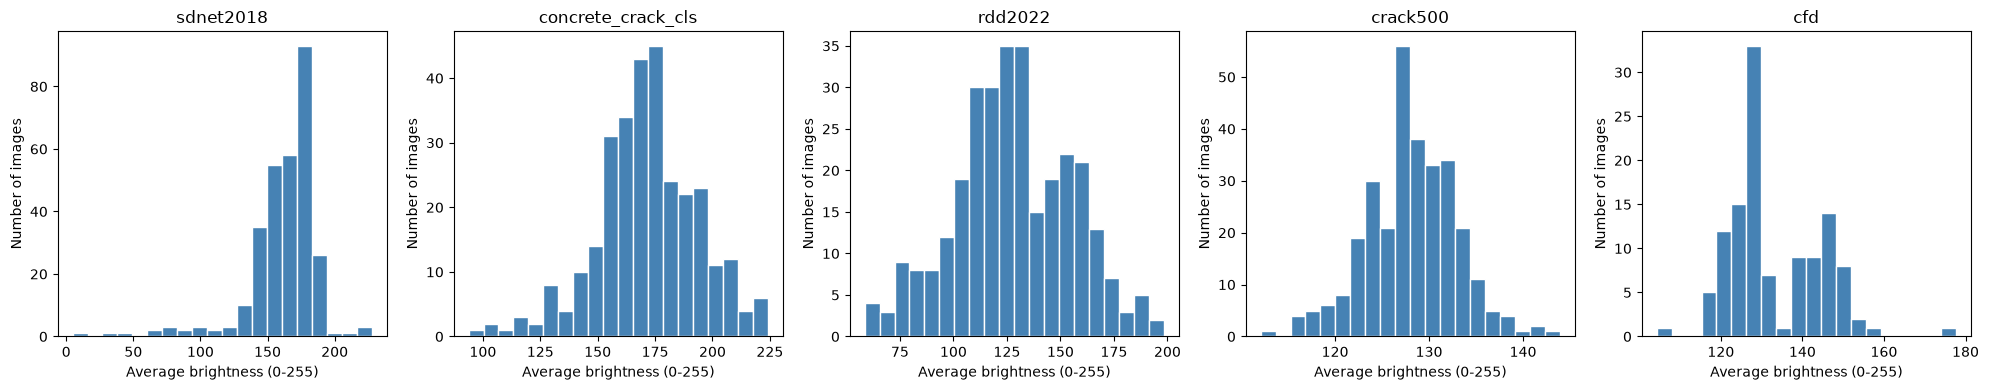

In [6]:
brightness_values = {}
for name in DATASET_NAMES:
    brightness_values[name] = []
    brightness_sample = choose_random_sample(valid_sampled_images[name], BRIGHTNESS_SAMPLE_SIZE)
    for image_path in brightness_sample:
        try:
            with Image.open(image_path) as image:
                small_gray = image.convert("L").resize((128, 128))
                brightness_values[name].append(float(np.asarray(small_gray).mean()))
        except (OSError, ValueError):
            continue
    print(f"{name}: brightness calculated for {len(brightness_values[name])} image(s)")

fig, axes = plt.subplots(1, len(DATASET_NAMES), figsize=(20, 4))
for axis, name in zip(axes, DATASET_NAMES):
    if brightness_values[name]:
        axis.hist(brightness_values[name], bins=20, color="steelblue", edgecolor="white")
    else:
        axis.text(0.5, 0.5, "No readable images", ha="center", va="center")
    axis.set_title(name)
    axis.set_xlabel("Average brightness (0-255)")
    axis.set_ylabel("Number of images")
plt.tight_layout()
plt.show()

## Step 5: Check labels and masks for every image

This checks all images, not only the sample. RDD2022 images are matched to XML by filename. Crack500 and CFD images are matched to mask filenames. Official RDD2022 test images may not have XML labels.

In [7]:
missing_label_counts = {}
label_details = {}
for name in DATASET_NAMES:
    image_paths = all_images[name]
    missing_paths = []
    detail = ""

    if name == "rdd2022":
        test_without_xml = 0
        for image_path in image_paths:
            image_folder = os.path.dirname(image_path)
            split_folder = os.path.dirname(image_folder)
            xml_path = os.path.join(split_folder, "annotations", "xmls", os.path.splitext(os.path.basename(image_path))[0] + ".xml")
            if not os.path.isfile(xml_path):
                missing_paths.append(image_path)
                if os.path.basename(split_folder).lower() == "test":
                    test_without_xml += 1
        detail = f"{test_without_xml} unlabeled test image(s); official test labels may not be included"
    elif name == "crack500":
        for image_path in image_paths:
            mask_path = os.path.join(os.path.dirname(image_path), os.path.splitext(os.path.basename(image_path))[0] + "_mask.png")
            if not os.path.isfile(mask_path):
                missing_paths.append(image_path)
    elif name == "cfd":
        folder = dataset_paths[name]
        mask_folders = [os.path.join(folder, entry) for entry in os.listdir(folder) if entry.lower() == "masks"] if folder else []
        mask_paths = glob.glob(os.path.join(mask_folders[0], "**", "*"), recursive=True) if mask_folders else []
        mask_stems = {os.path.splitext(os.path.basename(path))[0].lower() for path in mask_paths if os.path.isfile(path)}
        for image_path in image_paths:
            expected_stem = os.path.splitext(os.path.basename(image_path))[0].lower() + "_label"
            if expected_stem not in mask_stems:
                missing_paths.append(image_path)
    elif name == "sdnet2018":
        class_folders = {"cd", "cp", "cw", "ud", "up", "uw"}
        missing_paths = [path for path in image_paths if os.path.basename(os.path.dirname(path)).lower() not in class_folders]
    elif name == "concrete_crack_cls":
        class_folders = {"positive", "negative", "cracked", "uncracked"}
        missing_paths = [path for path in image_paths if os.path.basename(os.path.dirname(path)).lower() not in class_folders]

    missing_label_counts[name] = len(missing_paths)
    label_details[name] = detail
    print(f"{name}: {len(missing_paths)} image(s) without a matching label or mask out of {len(image_paths)}")
    if detail:
        print(" ", detail)
    for image_path in missing_paths[:3]:
        print("  Missing label for:", image_path)
    if len(missing_paths) > 3:
        print(f"  Plus {len(missing_paths) - 3} more")

sdnet2018: 0 image(s) without a matching label or mask out of 56092
concrete_crack_cls: 0 image(s) without a matching label or mask out of 40000
rdd2022: 9035 image(s) without a matching label or mask out of 47420
  9035 unlabeled test image(s); official test labels may not be included
  Missing label for: D:\Infosys springboards\data\raw\rdd2022\China_MotorBike\test\images\China_MotorBike_001977.jpg
  Missing label for: D:\Infosys springboards\data\raw\rdd2022\China_MotorBike\test\images\China_MotorBike_001978.jpg
  Missing label for: D:\Infosys springboards\data\raw\rdd2022\China_MotorBike\test\images\China_MotorBike_001979.jpg
  Plus 9032 more
crack500: 0 image(s) without a matching label or mask out of 500
cfd: 0 image(s) without a matching label or mask out of 118


## Step 6: Review the summary table

Sizes, broken images, and duplicates describe the random sample. Missing-label counts cover every image. Notes explain the sample size and expected unlabeled RDD2022 test images.

In [8]:
summary_rows = []
for name in DATASET_NAMES:
    dataset_notes = []
    if dataset_paths[name] is None:
        dataset_notes.append("Dataset folder is missing")
    if len(all_images[name]) > MAX_CHECK_IMAGES:
        dataset_notes.append(f"Quality and duplicate checks sampled {MAX_CHECK_IMAGES} of {len(all_images[name])}")
    elif all_images[name]:
        dataset_notes.append(f"Quality and duplicate checks sampled all {len(all_images[name])}")
    if label_details[name]:
        dataset_notes.append(label_details[name])
    summary_rows.append({
        "Dataset": name,
        "Total images": len(all_images[name]),
        "Sizes": dict(size_counts[name]),
        "Broken": broken_counts[name],
        "Duplicates": duplicate_counts[name],
        "Missing labels": missing_label_counts[name],
        "Notes": "; ".join(dataset_notes) if dataset_notes else "None noted",
    })

summary_table = pd.DataFrame(summary_rows, columns=["Dataset", "Total images", "Sizes", "Broken", "Duplicates", "Missing labels", "Notes"])
summary_table

,Dataset,Total images,Sizes,Broken,Duplicates,Missing labels,Notes
0,sdnet2018,56092,"{(256, 256): 2000}",0,0,0,Quality and duplicate checks sampled 2000 of 5...
1,concrete_crack_cls,40000,"{(227, 227): 2000}",0,5,0,Quality and duplicate checks sampled 2000 of 4...
2,rdd2022,47420,"{(600, 600): 651, (720, 720): 407, (640, 640):...",0,0,9035,Quality and duplicate checks sampled 2000 of 4...
3,crack500,500,"{(2560, 1440): 418, (3264, 2448): 36, (2592, 1...",0,0,0,Quality and duplicate checks sampled all 500
4,cfd,118,"{(480, 320): 118}",0,0,0,Quality and duplicate checks sampled all 118
